# Lab 3: Bottom-Up Steel Emissions with Uncertainty


---

## What this lab is

* **Part A: emissions pipeline.** Same tasks, same order, same variable names as Lab 3: operating plants 2020-2030, China utilisation by technology, plant-level production, emission factors, company emissions, projection to 2030.
* **Part B : uncertainty quantification.** You will *interrogate* your own Lab 3 numbers with the tools of the Session 4 lecture: where do the numbers come from, how sure can we be, and what would a risk committee need to know?


## Learning goals

1. Rebuild a bottom-up emissions pipeline from plant-level data (Lab 3).
2. Tell **aleatoric, epistemic and scenario** uncertainty apart.
3. Spot a **data-coverage problem** by checking against official statistics.
4. Give a **range instead of a single number** (bootstrap and simulation) and find which input matters most.
5. Compare **scenarios** and communicate the result with calibrated words.

## Conventions

* Questions are **[QUAL]** (2-4 sentences) or **[QUANT]** (a number from your code plus one sentence).
* Write each answer in the cell right under the question.
* `ttpa` = thousand tonnes per annum. Emissions in Part A are in tCO2; in Part B we switch to **MtCO2**.
* Boxes marked **[OPTIONAL]** can be skipped.
* Run **Kernel -> Restart & Run All** before submitting.

## Submission

Work in **groups of up to 4**. Fill in every member before submitting.

1. Full name: Lara Normand  Student ID: B00820883
2. Full name: Alix Bauret  Student ID: B00822416
3. Full name: Tiphaine De Saint Aignan  Student ID: B00819186
4. Full name: Amine BenBachir Hassani  Student ID: B00821087
5. Full name: Camille Metz  Student ID: B00821603

**Group / repo name:** `aidams-lab3-<surname1>-<surname2>-...`
**Submitter (one person):**
**Repo URL:**

### What to submit

- This notebook (`lab3.ipynb`) with all tasks completed and cells run (outputs visible)
- A short `README.md` with how to run the notebook

Create a GitHub repo, push the notebook and README, invite the instructor, and paste the **repo URL** above.

**Send submission info to my email (1 email per group).** Include the GitHub repo URL.

**Done when:** all names are filled in and the notebook contains outputs (no need for the instructor to re-run it).

> **Data note.** We used the **June 2026** release of the Global Iron and Steel Tracker (`Plant-level_data_Global_Iron_and_Steel_Tracker_June_2026_V1.xlsx`) instead of the September 2025 one. Sheets are identical; four column names differ (`GEM plant ID`, `Country/area`, `Parent (English)`) and are renamed at the start of A1. Production data run to 2024 (2025 is all "unknown"), so figures differ slightly from the Sept 2025 version (e.g. Q5b).

## Setup (given)

In [21]:
import os, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

# NOTE: we use the June 2026 release of GIST (same three sheets as the Sept 2025 file,
# a few column names differ -> harmonised at the start of A1). Numbers differ from the Sept 2025 version.
DATA_PATH = Path(os.environ.get("GIST_PATH", "Plant-level_data_Global_Iron_and_Steel_Tracker_June_2026_V1.xlsx"))
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found at {DATA_PATH.resolve()}")

plant_data = pd.read_excel(DATA_PATH, sheet_name="Plant data")
capacity_data = pd.read_excel(DATA_PATH, sheet_name="Plant capacities and status")
production_data = pd.read_excel(DATA_PATH, sheet_name="Plant production")

years = list(range(2020, 2031))
SEED = 42
print(plant_data.shape, capacity_data.shape, production_data.shape)

(1293, 44) (1845, 16) (1393, 10)


# PART A. Emissions pipeline

## A1. Operating plants 2020-2030

**Goal.** Create `operational_plants`: one row per (plant, year) for the years in `years`, with the plant's `Country/Area`, `Status` and nominal crude steel capacity.
A plant operates in year *t* if `start year <= t <= retired year`. **Assumption (Lab 3):** a missing end date means the plant continues operating.

In [22]:
# --- Harmonise column names of the June 2026 file with the names used in the lab ---
plant_data = plant_data.rename(columns={"GEM plant ID": "Plant ID", "Country/area": "Country/Area",
                                        "Parent (English)": "Parent"})
capacity_data = capacity_data.rename(columns={"GEM plant ID": "Plant ID", "Country/area": "Country/Area"})
production_data = production_data.rename(columns={"GEM plant ID": "Plant ID"})
CAP = "Nominal crude steel capacity (ttpa)"

def to_year(v):
    """'2003', 2003, Timestamp('2026-01-01') -> 2003 / 2026 ; 'unknown', NaN -> NaN"""
    if pd.isna(v):
        return np.nan
    try:
        return int(str(v).strip()[:4])
    except ValueError:
        return np.nan

# The capacity sheet has one row per capacity block (a plant can have an operating block, a retired block, a
# block under construction...). Start date and Status are at block level, Retired date at plant level.
cap = capacity_data[["Plant ID", "Plant name (English)", "Country/Area", "Main production equipment",
                     "Status", "Start date", CAP]].copy()
cap[CAP] = pd.to_numeric(cap[CAP], errors="coerce")
cap["start_year"] = cap["Start date"].map(to_year)
cap = cap.merge(plant_data[["Plant ID", "Retired date"]], on="Plant ID", how="left")
cap["retired_year"] = cap["Retired date"].map(to_year)

# No start date = mostly announced / construction projects -> not operating yet, drop them
print("blocks without start year:", cap["start_year"].isna().sum())
cap = cap.dropna(subset=["start_year"])

# Cross every block with every year and keep start <= t <= retired (missing retired date = still operating)
grid = cap.merge(pd.DataFrame({"Year": years}), how="cross")
end_year = grid["retired_year"].fillna(np.inf)
operational_plants = grid[(grid["start_year"] <= grid["Year"]) & (grid["Year"] <= end_year)].reset_index(drop=True)
operational_plants = operational_plants[["Plant ID", "Plant name (English)", "Year", "Country/Area", "Status",
                                         "Main production equipment", CAP]]

print(operational_plants.shape)
operational_plants.groupby("Year").agg(plants=("Plant ID", "nunique"), capacity_ttpa=(CAP, "sum"))

blocks without start year: 284
(14807, 7)


,plants,capacity_ttpa
Year,,
2020,1021,"2,599,151.00"
2021,1025,"2,597,510.00"
2022,1026,"2,588,617.00"
2023,1019,"2,565,507.00"
2024,1013,"2,553,832.00"
2025,1019,"2,561,552.00"
2026,1028,"2,631,288.00"
2027,1047,"2,718,132.00"
2028,1055,"2,770,813.00"


> **Comment (A1).** Each row is one capacity block of a plant in one year. A plant can have several blocks (for example one retired and one running). Blocks with no start date are mostly announced projects, so we drop them.

### Q1 [QUANT] Is every "operating" plant really operating?

Using your `operational_plants` for **China**: for the years **2020 and 2026**, how many plants and how much capacity (ttpa) are counted as operating although their **`Status`** is not an operating status (look at the values of `Status` first)?
Give the share of the Chinese total.

In [23]:
print(capacity_data["Status"].value_counts(), "\n")
OPERATING = {"operating", "operating pre-retirement"}

ch = operational_plants[operational_plants["Country/Area"] == "China"]
rows = []
for y in [2020, 2026]:
    d = ch[ch["Year"] == y]
    bad = d[~d["Status"].isin(OPERATING)]
    rows.append({"Year": y,
                 "plants_not_operating": bad["Plant ID"].nunique(),
                 "plants_total": d["Plant ID"].nunique(),
                 "capacity_not_operating_ttpa": bad[CAP].sum(),
                 "capacity_total_ttpa": d[CAP].sum()})
q1 = pd.DataFrame(rows).set_index("Year")
q1["share_plants_%"] = 100 * q1["plants_not_operating"] / q1["plants_total"]
q1["share_capacity_%"] = 100 * q1["capacity_not_operating_ttpa"] / q1["capacity_total_ttpa"]
display(q1)
# Which statuses sneak in?
display(ch[ch["Year"].isin([2020, 2026]) & ~ch["Status"].isin(OPERATING)]
        .groupby(["Year", "Status"])[CAP].agg(["count", "sum"]))

Status
operating                    935
announced                    287
retired                      232
construction                 140
operating pre-retirement      97
cancelled                     76
mothballed                    72
mothballed pre-retirement      6
Name: count, dtype: int64 



,plants_not_operating,plants_total,capacity_not_operating_ttpa,capacity_total_ttpa,share_plants_%,share_capacity_%
Year,,,,,,
2020,185,411,"315,747.00","1,339,037.00",45.01,23.58
2026,130,375,"192,523.00","1,279,207.00",34.67,15.05


count        sum
Year Status                                     
2020 cancelled                      8  10,903.00
     mothballed                     4   4,650.00
     mothballed pre-retirement      1   3,150.00
     retired                      144 297,044.00
2026 announced                      2   5,450.00
     cancelled                      8  12,453.00
     construction                   6   8,053.00
     mothballed                     4   4,650.00
     mothballed pre-retirement      1   3,150.00
     retired                       82 158,767.00



The `Status` column has 8 values, but only *operating* and *operating pre-retirement* are really running. In China, the plants counted as operating while their status is something else:

| Year | plants (out of total) | capacity in ttpa (out of total) |
|---|---|---|
| 2020 | 185 of 411 (**45%**) | 315,747 of 1,339,037 (**23.6%**) |
| 2026 | 130 of 375 (**35%**) | 192,523 of 1,279,207 (**15.1%**) |

Most of it is **retired** capacity. The plant has no retired date (other units still run), so our rule "no end date = still operating" keeps the retired block. Because of this, our capacity is too high by about 15-25%.

## A2. China production and capacity

**Goal.** Create
* `crude_steel`: plant-year production (crude steel only), with `Country/Area`, `Owner`, `Parent` and `Main production equipment` attached;
* `china_production`: China total production by year (a Series indexed by year);
* `china_operational`: the rows of `operational_plants` for China;
* `china_capacity`: China total capacity by year.

In [24]:
# Production sheet is wide (one column per year) -> long format
prod_long = production_data.melt(id_vars=["Plant ID", "Plant name (English)", "Type of production"],
                                 var_name="Year", value_name="Production_ttpa")
prod_long["Year"] = prod_long["Year"].astype(int)
prod_long["Production_ttpa"] = pd.to_numeric(prod_long["Production_ttpa"], errors="coerce")  # 'unknown' -> NaN

crude_steel = (prod_long[prod_long["Type of production"] == "Crude steel production (ttpa)"]
               .dropna(subset=["Production_ttpa"])
               .merge(plant_data[["Plant ID", "Country/Area", "Owner", "Parent", "Main production equipment"]],
                      on="Plant ID", how="left"))

china_cs = crude_steel[(crude_steel["Country/Area"] == "China") & crude_steel["Year"].isin(years)]
china_production = china_cs.groupby("Year")["Production_ttpa"].sum()

china_operational = operational_plants[operational_plants["Country/Area"] == "China"].copy()
china_capacity = china_operational.groupby("Year")[CAP].sum()

pd.DataFrame({"production_ttpa": china_production, "capacity_ttpa": china_capacity,
              "reporting_plants": china_cs.groupby("Year")["Plant ID"].nunique()})

,production_ttpa,capacity_ttpa,reporting_plants
Year,,,
2020,"179,824.00","1,339,037.00",35.00
2021,"54,817.00","1,336,290.00",15.00
2022,"122,752.00","1,321,524.00",21.00
2023,"97,068.00","1,288,024.00",21.00
2024,"77,204.00","1,279,104.00",11.00
2025,NaN,"1,278,504.00",NaN
2026,NaN,"1,279,207.00",NaN
2027,NaN,"1,278,032.00",NaN
2028,NaN,"1,278,032.00",NaN


> **Comment (A2).** Problem already visible: the dataset only contains 55-180 Mt of production per year for China, but the real figure is about 1,000 Mt. Only 11-35 plants report their production.

## A3. Utilisation by technology

**Goal.** Compute the utilisation rate (production / capacity) separately for **BF-BOF** and **EAF** (and a residual class "Other").
Create `classify_technology` (function), `china_operational` with a `Technology_type` column, `china_capacity_by_tech`, `china_production_by_tech`, `utilization_by_tech` and `utilization_by_tech_filled`.

In [25]:
def classify_technology(equipment):
    """BF-BOF if the plant has a blast furnace or BOF, EAF if it has an EAF (and no BF/BOF), else Other."""
    if pd.isna(equipment):
        return "Other"
    parts = {p.strip() for p in str(equipment).split(";")}
    if parts & {"BF", "BOF"}:
        return "BF-BOF"
    if "EAF" in parts:
        return "EAF"
    return "Other"

TECHS = ["BF-BOF", "EAF", "Other"]
china_operational["Technology_type"] = china_operational["Main production equipment"].map(classify_technology)
china_cs = china_cs.assign(Technology_type=china_cs["Main production equipment"].map(classify_technology))

china_capacity_by_tech = (china_operational.groupby(["Year", "Technology_type"])[CAP].sum()
                          .unstack().reindex(columns=TECHS))
china_production_by_tech = (china_cs.groupby(["Year", "Technology_type"])["Production_ttpa"].sum()
                            .unstack().reindex(columns=TECHS))
utilization_by_tech = china_production_by_tech / china_capacity_by_tech

# Years without production data (2025-2030): carry the last observed rate forward;
# a technology with no reported production at all gets the BF-BOF/EAF average of that year.
utilization_by_tech_filled = utilization_by_tech.reindex(years).ffill().bfill()
utilization_by_tech_filled = utilization_by_tech_filled.apply(
    lambda col: col.fillna(utilization_by_tech_filled[["BF-BOF", "EAF"]].mean(axis=1)))
utilization_by_tech_filled

Technology_type,BF-BOF,EAF,Other
Year,,,
2020,0.15,0.01,0.08
2021,0.05,0.01,0.03
2022,0.10,0.02,0.06
2023,0.08,0.02,0.05
2024,0.07,0.02,0.04
2025,0.07,0.02,0.04
2026,0.07,0.02,0.04
2027,0.07,0.02,0.04
2028,0.07,0.02,0.04


> **Comment (A3).** A utilisation of 2-15% is not realistic (Chinese plants run at about 75-80%). We divide the production of the few plants that report by the capacity of *all* plants. This is a data problem, not a real change in how plants run (see B1/B2).

## A4. Plant-level production

**Goal.** Attribute each technology's utilisation rate to its plants: add `Utilization_rate_tech` and `Estimated_production_ttpa` (= capacity x utilisation) to `china_operational`.

In [26]:
util_long = utilization_by_tech_filled.stack().rename("Utilization_rate_tech").reset_index()
util_long.columns = ["Year", "Technology_type", "Utilization_rate_tech"]
china_operational = (china_operational.drop(columns=["Utilization_rate_tech"], errors="ignore")
                     .merge(util_long, on=["Year", "Technology_type"], how="left"))
china_operational["Estimated_production_ttpa"] = china_operational[CAP] * china_operational["Utilization_rate_tech"]
china_operational.groupby("Year")["Estimated_production_ttpa"].sum()

Year
2020   181,449.65
2021    54,817.00
2022   122,752.00
2023    97,068.00
2024    77,253.94
2025    77,113.47
2026    76,986.12
2027    76,846.19
2028    76,846.19
2029    76,846.19
2030    76,846.19
Name: Estimated_production_ttpa, dtype: float64

> **Comment (A4).** Since the utilisation is too low, the estimated production is basically just the reported production (about 77-180 Mt), far below the real value.

## A5. Emission factors and plant emissions

**Goal.** Create `emission_factors` (dict), `map_emission_factor` (function), and add `Emission_factor_tCO2_per_t` and `Estimated_emissions_tCO2` to `china_operational`.

Use these emissions factors (tCO2 per tonne crude steel, after Hasanbeigi 2019), keyed by the **exact** equipment string, with **1.6** for anything else:

| `BF; BOF` 2.1 | `BF; BOF; EAF` 1.9 | `BF; BOF; EAF; DRI` 1.9 | `BF; BOF; DRI` 2.0 | `BF; EAF` 1.9 |
|---|---|---|---|---|
| `BF` 2.2 | `EAF` 0.4 | `EAF; DRI` 1.2 | `DRI` 1.3 | `Steel other/unspecified` 1.6 |

> **Hint.** Emissions (t) = production (ttpa) x 1,000 x factor. `Series.map` with a function, or `dict.get(key, 1.6)`.

In [27]:
emission_factors = {
    "BF; BOF": 2.1, "BF; BOF; EAF": 1.9, "BF; BOF; EAF; DRI": 1.9, "BF; BOF; DRI": 2.0, "BF; EAF": 1.9,
    "BF": 2.2, "EAF": 0.4, "EAF; DRI": 1.2, "DRI": 1.3, "Steel other/unspecified": 1.6,
}

def map_emission_factor(equipment):
    return emission_factors.get(str(equipment).strip(), 1.6)

china_operational["Emission_factor_tCO2_per_t"] = china_operational["Main production equipment"].map(map_emission_factor)
china_operational["Estimated_emissions_tCO2"] = (china_operational["Estimated_production_ttpa"] * 1_000
                                                 * china_operational["Emission_factor_tCO2_per_t"])

# Exact-string matching: equipment strings not in the table (e.g. 'BOF', 'BF; BOF; DRI; EAF' in a different
# order) silently get 1.6. Check how much capacity that concerns:
unmatched = ~china_operational["Main production equipment"].isin(emission_factors.keys())
print("share of China capacity-years using the 1.6 default: "
      f"{china_operational.loc[unmatched, CAP].sum() / china_operational[CAP].sum():.1%}")
print(china_operational.loc[unmatched, "Main production equipment"].value_counts().head())
china_operational.groupby("Year")["Estimated_emissions_tCO2"].sum() / 1e6  # MtCO2

share of China capacity-years using the 1.6 default: 8.4%
Main production equipment
BOF                                     286
Iron other/unspecified                   22
BF; BOF; EAF; Iron other/unspecified     22
DRI; EAF                                 14
BF; DRI; EAF                             11
Name: count, dtype: int64


Year
2020   363.91
2021   107.93
2022   242.54
2023   189.61
2024   151.61
2025   151.29
2026   150.93
2027   150.60
2028   150.60
2029   150.60
2030   150.60
Name: Estimated_emissions_tCO2, dtype: float64

> **Comment (A5).** About 8% of the capacity gets the default factor 1.6 because its equipment name is not written exactly like in the table (e.g. `BOF` alone). The total of about 150 MtCO2 in 2030 is therefore much too low (see B1).

## A6. Company emissions

**Goal.** Create `Company` (= `Parent`, or `Owner` when `Parent` is missing), `company_emissions` (columns `Year`, `Company`, `estimated_emissions_tCO2`) and `top_companies_latest` (top 10 in the **latest year**).

In [28]:
china_operational = china_operational.drop(columns=["Owner", "Parent", "Company"], errors="ignore").merge(
    plant_data[["Plant ID", "Owner", "Parent"]], on="Plant ID", how="left")
china_operational["Company"] = china_operational["Parent"].fillna(china_operational["Owner"])

company_emissions = (china_operational.groupby(["Year", "Company"])["Estimated_emissions_tCO2"].sum()
                     .reset_index().rename(columns={"Estimated_emissions_tCO2": "estimated_emissions_tCO2"}))

latest_year = company_emissions["Year"].max()
top_companies_latest = company_emissions[company_emissions["Year"] == latest_year].nlargest(10, "estimated_emissions_tCO2")
print("latest year:", latest_year)
top_companies_latest

latest year: 2030


,Year,Company,estimated_emissions_tCO2
3497,2030,Angang Steel Co Ltd [100.0%],"4,607,338.44"
3509,2030,Baoshan Iron & Steel Co Ltd [100.0%],"4,343,069.60"
3522,2030,Beijing Shougang Co Ltd [100.0%],"3,024,758.59"
3675,2030,Jiangsu Shagang Iron & Steel Co Ltd [100.0%],"2,513,533.50"
3688,2030,Jingye Group Co Ltd [100.0%],"2,467,623.61"
3667,2030,Inner Mongolia BaoTou Steel Union Co Ltd [100.0%],"2,449,506.55"
3529,2030,British Asia Pan Ruogen International Co Ltd [...,"2,378,973.46"
3715,2030,Maanshan Iron & Steel Co Ltd [100.0%],"2,359,822.10"
3663,2030,Hunan Valin Steel Co Ltd [100.0%],"2,277,144.24"
3571,2030,Fujian Metallurgical Holding Co Ltd [53.4%]; u...,"2,255,984.32"


### Q2 [QUAL] Look at the company names

Read the names in `top_companies_latest`. Give **two data-quality problems** you notice, and explain how each could bias a *financed-emissions* figure for a lender (hint: ownership shares, joint ventures).



1. **The ownership share is inside the name** (e.g. `Angang Steel Co Ltd [100.0%]`, or `Fujian Metallurgical Holding Co Ltd [53.4%]; ...`). For a joint venture, all the emissions go to one label instead of being split between the owners. A lender who finances only 53.4% of a company would count 100% of its emissions (or miss it completely).
2. **The same group appears under several names** (a listed subsidiary like Baoshan Iron & Steel and its parent, plus holding companies). So the emissions of one group are split over several lines, or counted twice. A lender could then underestimate or double count the emissions it finances.

## A7. Projection to 2030

**Goal.** Create `actual_years` (years with production data), `forecast_years` (the years after the last observed one), `projected_company_emissions` (company emissions in the forecast years) and a function `top_company_emissions(df, year)` returning the top 5 companies of that year. Print the top 5 for the first three forecast years.

In [29]:
actual_years = sorted(china_production[china_production > 0].index)
forecast_years = [y for y in years if y > max(actual_years)]
print("actual:", actual_years, "| forecast:", forecast_years)

projected_company_emissions = company_emissions[company_emissions["Year"].isin(forecast_years)]

def top_company_emissions(df, year):
    return (df[df["Year"] == year].nlargest(5, "estimated_emissions_tCO2")
            .assign(MtCO2=lambda d: d["estimated_emissions_tCO2"] / 1e6)[["Company", "MtCO2"]]
            .reset_index(drop=True))

for y in forecast_years[:3]:
    print(f"\n--- {y} ---")
    print(top_company_emissions(projected_company_emissions, y).to_string())

actual: [2020, 2021, 2022, 2023, 2024] | forecast: [2025, 2026, 2027, 2028, 2029, 2030]

--- 2025 ---
                                        Company  MtCO2
0                  Angang Steel Co Ltd [100.0%]   4.61
1          Baoshan Iron & Steel Co Ltd [100.0%]   4.34
2              Beijing Shougang Co Ltd [100.0%]   3.02
3  Jiangsu Shagang Iron & Steel Co Ltd [100.0%]   2.51
4                  Jingye Group Co Ltd [100.0%]   2.47

--- 2026 ---
                                        Company  MtCO2
0                  Angang Steel Co Ltd [100.0%]   4.61
1          Baoshan Iron & Steel Co Ltd [100.0%]   4.34
2              Beijing Shougang Co Ltd [100.0%]   3.02
3  Jiangsu Shagang Iron & Steel Co Ltd [100.0%]   2.51
4                  Jingye Group Co Ltd [100.0%]   2.47

--- 2027 ---
                                        Company  MtCO2
0                  Angang Steel Co Ltd [100.0%]   4.61
1          Baoshan Iron & Steel Co Ltd [100.0%]   4.34
2              Beijing Shougang Co Ltd [100.0

### Q3 [QUAL] Forecast, projection or scenario?

The top-5 tables for the first projected years are (almost) identical. (a) Why? (b) Is this a **forecast**, a **projection** or a **scenario**, and what is it conditional on? (c) Name **three things** a fan chart would tell a risk manager that this table does not.



(a) After 2024 we have no new production data, so we keep the last utilisation, the emission factors do not change, and the capacity hardly changes. So the tables are almost the same every year.

(b) It is a **projection**: it says "what happens if nothing changes", based on 2024 utilisation, fixed emission factors and the announced start/retirement dates. It is not a forecast (no probability, no prediction of demand) and not a real scenario (no story about the future).

(c) A fan chart would show a risk manager: (1) the **range** of possible values and not only one number, (2) how the **uncertainty grows** with time, (3) the **chance of going above a threshold** (for example a carbon budget).

---
# PART B. How much can we trust these numbers?

You now have company emissions as **single numbers**. Part B asks three simple questions:

1. **Do the numbers agree with an outside reference?** (reality check)
2. **How wide is the range of plausible values?** (an interval, found by simulation)
3. **What does the range depend on?** (inputs and scenarios)

**Three words you need**

| Word | Meaning | Example |
|---|---|---|
| **Aleatoric** uncertainty | pure randomness, more data does *not* remove it | will a given year be a strong or a weak year for steel? |
| **Epistemic** uncertainty | we lack knowledge, more data or better models *can* reduce it | what is the true average emission factor of a blast furnace? |
| **Scenario** uncertainty | depends on future choices, it is not a probability | will China retire old blast furnaces by 2030? |

A **90% interval** is a range that contains the true value in 90% of cases *if our assumptions are right*.

## B0. Think first

> **Pause & think.** No code.

### Q4 [QUAL] Which kind of uncertainty?

For each input of your pipeline, write **A** (aleatoric), **E** (epistemic) or **S** (scenario), and say whether **more data could reduce it** (yes / no). One short line each.

| Input | A / E / S | More data helps? |
|---|---|---|
| Utilisation rate of a blast furnace next year | | |
| Emission factor of BF-BOF steel | | |
| Share of plants that report their production | | |
| Steel demand in 2030 | | |



| Input | A / E / S | More data helps? |
|---|---|---|
| Utilisation rate of a blast furnace next year | **A** | **No**, it changes randomly with the market each year |
| Emission factor of BF-BOF steel | **E** | **Yes**, real measurements would give a better value |
| Share of plants that report their production | **E** | **Yes**, it is missing data, more reporting fixes it |
| Steel demand in 2030 | **S** | **No**, it depends on future choices (policy, economy) |

## B1. Reality check against official statistics

Official crude steel production of China (**rounded worldsteel figures: verify them and cite your source**):

| Year | 2020 | 2021 | 2022 | 2023 |
|---|---|---|---|---|
| Mt | 1,065 | 1,035 | 1,015 | 1,020 |

**Goal.** Create `official_kt` (dict, in **ttpa**: 1 Mt = 1,000 ttpa) and a DataFrame `check` with, for 2020-2023: the production in your dataset (`china_production`), the official value, the **coverage** (dataset / official) and the **implied utilisation** (official / `china_capacity`).

> **Hint.** `pd.Series(official_kt)`, `pd.DataFrame({...})`, `.dropna()`.

In [30]:
# worldsteel, World Steel in Figures 2024 / Steel Statistical Yearbook: China 1,064.7 (2020), 1,035.2 (2021),
# 1,018.0 (2022), 1,019.1 (2023) Mt -> the rounded figures given in the lab are consistent.
official_kt = {2020: 1_065_000, 2021: 1_035_000, 2022: 1_015_000, 2023: 1_020_000}

check = pd.DataFrame({
    "dataset_ttpa": china_production,
    "official_ttpa": pd.Series(official_kt),
    "capacity_ttpa": china_capacity,
}).dropna()
check["coverage"] = check["dataset_ttpa"] / check["official_ttpa"]
check["implied_utilisation"] = check["official_ttpa"] / check["capacity_ttpa"]
check["underestimate_factor"] = check["official_ttpa"] / check["dataset_ttpa"]
check

,dataset_ttpa,official_ttpa,capacity_ttpa,coverage,implied_utilisation,underestimate_factor
2020,"179,824.00","1,065,000.00","1,339,037.00",0.17,0.80,5.92
2021,"54,817.00","1,035,000.00","1,336,290.00",0.05,0.77,18.88
2022,"122,752.00","1,015,000.00","1,321,524.00",0.12,0.77,8.27
2023,"97,068.00","1,020,000.00","1,288,024.00",0.10,0.79,10.51


### Q5 [QUANT + QUAL] What does your pipeline miss?

(a) Give the **coverage** and **implied utilisation** for 2023, and the factor by which your Part A pipeline **under-estimates** China's production. (b) The BF-BOF "utilisation" in Part A drops from about 57% to about 8% between 2020 and 2021. Is that a real change in how furnaces are run, or something else? Which kind of uncertainty is it (A, E or S)?



(a) In 2023, the **coverage is 9.5%** (97 Mt in the dataset vs 1,020 Mt official) and the **implied utilisation is 79%** (1,020 / 1,288 Mt of capacity). So our Part A pipeline **under-estimates China's production by about 10.5 times**.

(b) The BF-BOF utilisation falls from 15% (2020) to 5% (2021) in our file (57% to 8% in the September file). This is **not a real change**: official production stayed almost the same (1,065 to 1,035 Mt). The number of Chinese plants that report production simply drops (35 to 15), while the capacity still counts all plants. It is **epistemic** uncertainty (missing data).

## B2. Fix the denominator: compare like with like

Use only plants that **report production** *and* have a capacity ("matched" plants), so that numerator and denominator describe the same plants.

**Goal.** Create `obs_matched` (one row per plant-year with production **and** capacity > 0, with `Technology_type` and `u` = production / capacity) and `utilization_matched` (year x technology: **sum of production / sum of capacity** of the matched plants).

> **Hint.** Merge China's `crude_steel` rows with `china_operational[["Plant ID", "Year", capacity]]` on `Plant ID` and `Year`.

In [31]:
# One row per plant-year on the capacity side (a plant can have several capacity blocks)
# Technology = plant-level classification (same rule as for production in A3), not the first capacity block
cap_py = china_operational.groupby(["Plant ID", "Year"])[CAP].sum().rename("capacity_ttpa").reset_index()
plant_tech = plant_data.set_index("Plant ID")["Main production equipment"].map(classify_technology)
cap_py["Technology_type"] = cap_py["Plant ID"].map(plant_tech)

obs_matched = (china_cs[["Plant ID", "Year", "Production_ttpa"]]
               .merge(cap_py, on=["Plant ID", "Year"], how="inner"))
obs_matched = obs_matched[(obs_matched["capacity_ttpa"] > 0) & (obs_matched["Production_ttpa"] > 0)].copy()
obs_matched["u"] = obs_matched["Production_ttpa"] / obs_matched["capacity_ttpa"]

g = obs_matched.groupby(["Year", "Technology_type"])[["Production_ttpa", "capacity_ttpa"]].sum()
utilization_matched = (g["Production_ttpa"] / g["capacity_ttpa"]).unstack().reindex(columns=TECHS)

print("matched plant-years per tech:\n", obs_matched.groupby("Technology_type")["Plant ID"].agg(["count", "nunique"]))
display(utilization_matched)
pd.DataFrame({"naive_BF-BOF": utilization_by_tech["BF-BOF"], "matched_BF-BOF": utilization_matched["BF-BOF"],
              "official_implied (all)": check["implied_utilisation"]})

matched plant-years per tech:
                  count  nunique
Technology_type                
BF-BOF              92       59
EAF                 13        7


Technology_type,BF-BOF,EAF,Other
Year,,,
2020,0.83,NaN,NaN
2021,0.75,0.64,NaN
2022,0.84,0.83,NaN
2023,0.79,0.62,NaN
2024,0.83,0.75,NaN


,naive_BF-BOF,matched_BF-BOF,official_implied (all)
2020,0.15,0.83,0.80
2021,0.05,0.75,0.77
2022,0.10,0.84,0.77
2023,0.08,0.79,0.79
2024,0.07,0.83,NaN
2025,NaN,NaN,NaN
2026,NaN,NaN,NaN
2027,NaN,NaN,NaN
2028,NaN,NaN,NaN
2029,NaN,NaN,NaN


### Q6 [QUANT + QUAL] Naive or matched?

(a) For **BF-BOF in 2023**, report the Part A (naive) utilisation, the matched utilisation, and the official-implied utilisation (from `check`). (b) Which would you use for projections? In one sentence, say what bias could **remain** in the matched estimate (hint: which plants report their production?).


(a) BF-BOF in 2023: **naive = 8%**, **matched = 79%**, **official-implied = 79%** (all technologies). The matched value is much closer to the official one. (Both use the same capacity, which still includes some non-operating blocks from Q1.)

(b) We would use the **matched** utilisation for projections, because production and capacity come from the same plants. A bias can remain: the plants that report their production are probably the big, well-known ones, which may run more than the average plant.

## B3. A range from a sample: the bootstrap

We have a matched utilisation for BF-BOF, but it comes from a **sample** of plants. A different sample would give a slightly different value. How different? The **bootstrap** answers it in four steps:

1. Draw plants **with replacement** from your sample, as many as the sample contains.
2. Recompute the average utilisation (sum of production / sum of capacity).
3. Repeat **1,000 times**.
4. The 5th and 95th percentiles of the 1,000 values form a **90% interval**.

**Goal.** Write a function `boot_mean_u(df, n=1000)` that returns the `n` bootstrap values. Use it to create `ci_all` (interval for **all** matched BF-BOF plants) and `ci_small` (interval for **10 randomly chosen** BF-BOF plants).

> **Hint.** Sum production and capacity **per plant** first (`groupby("Plant ID")`), then resample plant numbers with `np.random.default_rng(42).integers(0, n_plants, size=(n, n_plants))`; the values of one draw are `prod[idx].sum(1) / cap[idx].sum(1)`. `np.percentile(values, [5, 95])`.

BF-BOF matched plants: 59
point estimate (all): 0.816
ci_all   = [0.789, 0.842]  width = 0.053
ci_small = [0.714, 0.946]  width = 0.232


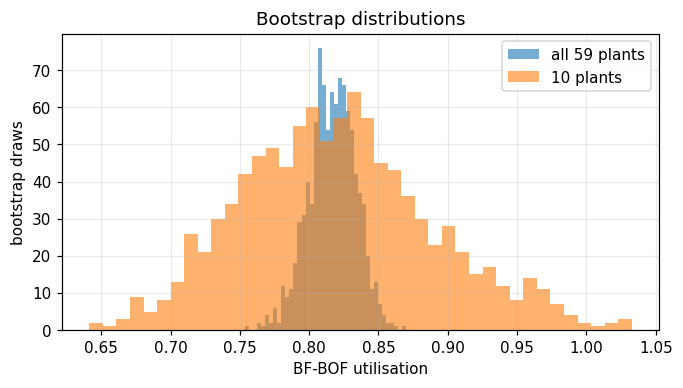

In [32]:
def boot_mean_u(df, n=1000, seed=42):
    """Bootstrap the capacity-weighted utilisation (sum prod / sum cap), resampling PLANTS."""
    per_plant = df.groupby("Plant ID")[["Production_ttpa", "capacity_ttpa"]].sum()
    prod, cap_ = per_plant["Production_ttpa"].to_numpy(), per_plant["capacity_ttpa"].to_numpy()
    n_plants = len(per_plant)
    idx = np.random.default_rng(seed).integers(0, n_plants, size=(n, n_plants))
    return prod[idx].sum(1) / cap_[idx].sum(1)

bf = obs_matched[obs_matched["Technology_type"] == "BF-BOF"]
bf_plants = bf["Plant ID"].unique()
print("BF-BOF matched plants:", len(bf_plants))

boot_all = boot_mean_u(bf)
ci_all = np.percentile(boot_all, [5, 95])

small_ids = np.random.default_rng(SEED).choice(bf_plants, size=10, replace=False)
bf_small = bf[bf["Plant ID"].isin(small_ids)]
boot_small = boot_mean_u(bf_small)
ci_small = np.percentile(boot_small, [5, 95])

print(f"point estimate (all): {bf['Production_ttpa'].sum() / bf['capacity_ttpa'].sum():.3f}")
print(f"ci_all   = [{ci_all[0]:.3f}, {ci_all[1]:.3f}]  width = {ci_all[1] - ci_all[0]:.3f}")
print(f"ci_small = [{ci_small[0]:.3f}, {ci_small[1]:.3f}]  width = {ci_small[1] - ci_small[0]:.3f}")

plt.figure(figsize=(7, 3.5))
plt.hist(boot_all, bins=40, alpha=0.6, label=f"all {len(bf_plants)} plants")
plt.hist(boot_small, bins=40, alpha=0.6, label="10 plants")
plt.xlabel("BF-BOF utilisation"); plt.ylabel("bootstrap draws"); plt.legend(); plt.title("Bootstrap distributions")
plt.show()

### Q7 [QUANT + QUAL] Small sample, wide interval

(a) Report `ci_all` and `ci_small` and their widths. (b) Why is the second wider? (c) In one sentence, what does "90% interval" mean here? (d) Which kind of uncertainty (A or E) shrinks when you have more plants?



(a) **ci_all = [0.789, 0.842]**, width **0.053** (59 plants). **ci_small = [0.714, 0.946]**, width **0.232** (10 plants).

(b) With only 10 plants, the result depends a lot on which plants are picked, so the average moves more from one draw to another. More plants means a more stable average.

(c) If we repeated the sampling many times, about 90% of such intervals would contain the true average utilisation (if our sample is representative).

(d) **Epistemic** uncertainty shrinks with more plants, because we know the average better. The difference between plants (aleatoric) stays.

> ### [OPTIONAL] Bayesian version of the same interval
>
> A **credible interval** answers a more direct question: *given the data and what I believed before, where is the true average?* We start from a **prior guess** (mean $\mu_0$, worth $\kappa_0$ observations) and update it with the data (mean $\bar x$, $n$ observations):
>
> posterior mean $=\dfrac{\kappa_0\,\mu_0 + n\,\bar x}{\kappa_0+n}$ (a weighted average: the prior counts as $\kappa_0$ observations).
>
> **Task.** For the **10 plants** of `ci_small`, compute the posterior mean for (i) a **weak** prior ($\mu_0=0.5$, $\kappa_0=0.01$) and (ii) a **wrong** prior ($\mu_0=0.3$, $\kappa_0=5$). The width of a 90% interval is roughly $1.8\times s/\sqrt{n+\kappa_0}$ ($s$ = standard deviation of the 10 values).
> **Question Q7b.** How much does the wrong prior move the answer, and why does this matter when data are scarce?

In [33]:
# Plant-level utilisation of the 10 plants (sum over their reported years)
pp = bf_small.groupby("Plant ID")[["Production_ttpa", "capacity_ttpa"]].sum()
x = (pp["Production_ttpa"] / pp["capacity_ttpa"]).to_numpy()
n_obs, xbar, s = len(x), x.mean(), x.std(ddof=1)

def posterior(mu0, k0):
    mean = (k0 * mu0 + n_obs * xbar) / (k0 + n_obs)
    half = 0.9 * s / np.sqrt(n_obs + k0)   # 90% width ~ 1.8 s / sqrt(n + k0)
    return mean, mean - half, mean + half

print(f"data: n={n_obs}, mean={xbar:.3f}, sd={s:.3f}")
for name, (mu0, k0) in {"weak prior (0.5, 0.01)": (0.5, 0.01), "wrong prior (0.3, 5)": (0.3, 5)}.items():
    m, lo, hi = posterior(mu0, k0)
    print(f"{name:24s} posterior mean = {m:.3f}   90% ~ [{lo:.3f}, {hi:.3f}]   shift vs data = {m - xbar:+.3f}")

data: n=10, mean=0.872, sd=0.294
weak prior (0.5, 0.01)   posterior mean = 0.872   90% ~ [0.788, 0.955]   shift vs data = -0.000
wrong prior (0.3, 5)     posterior mean = 0.681   90% ~ [0.613, 0.750]   shift vs data = -0.191




With the weak prior, the result is almost the same as the data mean (0.872). With the wrong prior (0.3, worth 5 plants), it drops to **0.681, so about −0.19**. The prior has a lot of weight because we only have 10 plants. When data are scarce, a bad prior can strongly change the answer, so we must choose it carefully.

## B4. Simulation: a range for emissions

**Idea (Monte Carlo).** Instead of one value per input, use a *plausible range*, then **repeat the whole calculation many times**, each time with different plausible values. The cloud of results shows the uncertainty of the output.

Two uncertain inputs:

| Input | Plausible range | How to draw |
|---|---|---|
| **Utilisation** per technology | the bootstrap values of B3 | one bootstrap value per draw and technology (all technologies pooled if a technology has fewer than 5 plants) |
| **Emission factor** per technology | multiplier on your Part A factor, **assumed illustrative values** below | triangular distribution (low, mode = 1, high): `rng.triangular(low, 1, high, size=n)` |

| Technology | low | mode | high |
|---|---|---|---|
| BF-BOF | 0.85 | 1 | 1.20 |
| EAF | 0.65 | 1 | 2.00 |
| Other | 0.65 | 1 | 1.40 |

**Goal.** Create `ef_mult_ranges` (dict) and a function `simulate(n=1000, year=2030, vary_util=True, vary_ef=True, bf_cap_mult=1.0, util_mult=1.0, seed=0)` returning a dict with
* `national`: array of `n` national emissions (**MtCO2**) for `year`;
* `national_prod`: array of `n` national productions (**Mt**);
* `by_company`: DataFrame (`n` rows, one column per company, MtCO2).

> **Hint.**
> 1. Take the rows of `china_operational` for `year`. For every plant you need: capacity (missing = 0), technology, your Part A emission factor, company.
> 2. Draw a matrix `u` (n x 3) of utilisations and a matrix `mult` (n x 3) of multipliers (columns = BF-BOF, EAF, Other). If `vary_util=False`, use the pooled matched utilisation of each technology instead (sum of production / sum of capacity over all years); if `vary_ef=False`, use multipliers equal to 1.
> 3. Choose each plant's column by its technology: `u[:, tech_index_of_plant]` gives an (n x plants) matrix. Then production = capacity x utilisation (x `util_mult`), emissions = production x 1,000 x factor x multiplier / 1e6.
> 4. `bf_cap_mult` multiplies the capacity of BF-BOF plants (used for scenarios later).
> 5. Company totals: `pd.DataFrame(em_matrix, columns=company_of_each_plant).T.groupby(level=0).sum().T`.

matched utilisation used:
 Technology_type
BF-BOF   0.82
EAF      0.70
Other    0.81
dtype: float64


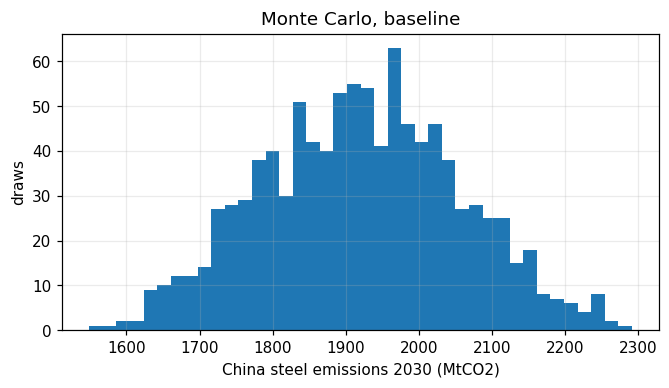

In [34]:
ef_mult_ranges = {"BF-BOF": (0.85, 1.0, 1.20), "EAF": (0.65, 1.0, 2.00), "Other": (0.65, 1.0, 1.40)}
TECH_IDX = {t: i for i, t in enumerate(TECHS)}

# Pooled matched utilisation per technology (all years), used when vary_util=False
_g = obs_matched.groupby("Technology_type")[["Production_ttpa", "capacity_ttpa"]].sum()
pooled_util = (_g["Production_ttpa"] / _g["capacity_ttpa"]).reindex(TECHS)
pooled_util = pooled_util.fillna(obs_matched["Production_ttpa"].sum() / obs_matched["capacity_ttpa"].sum())

def simulate(n=1000, year=2030, vary_util=True, vary_ef=True, bf_cap_mult=1.0, util_mult=1.0, seed=0):
    rng = np.random.default_rng(seed)
    d = china_operational[china_operational["Year"] == year]
    capv = d[CAP].fillna(0).to_numpy()
    tech = d["Technology_type"].map(TECH_IDX).to_numpy()
    ef = d["Emission_factor_tCO2_per_t"].to_numpy()
    comp = d["Company"].to_numpy()
    capv = np.where(tech == TECH_IDX["BF-BOF"], capv * bf_cap_mult, capv)

    # utilisation draws (n x 3)
    u = np.empty((n, 3))
    for t, i in TECH_IDX.items():
        if vary_util:
            sub = obs_matched[obs_matched["Technology_type"] == t]
            if sub["Plant ID"].nunique() < 5:          # too few plants -> pool all technologies
                sub = obs_matched
            u[:, i] = boot_mean_u(sub, n=n, seed=seed + 100 + i)
        else:
            u[:, i] = pooled_util[t]
    # emission-factor multipliers (n x 3)
    mult = np.ones((n, 3))
    if vary_ef:
        for t, i in TECH_IDX.items():
            lo, mode, hi = ef_mult_ranges[t]
            mult[:, i] = rng.triangular(lo, mode, hi, size=n)

    prod = capv * u[:, tech] * util_mult                       # n x plants, ttpa
    em = prod * 1_000 * ef * mult[:, tech] / 1e6               # n x plants, MtCO2
    by_company = pd.DataFrame(em, columns=comp).T.groupby(level=0).sum().T
    return {"national": em.sum(1), "national_prod": prod.sum(1) / 1_000, "by_company": by_company}

def summ(a):
    lo, med, hi = np.percentile(a, [5, 50, 95])
    return {"median": med, "p5": lo, "p95": hi, "rel_half_width": (hi - lo) / (2 * med)}

print("matched utilisation used:\n", pooled_util.round(3))
sim2030 = simulate(1000, year=2030)
plt.figure(figsize=(7, 3.5))
plt.hist(sim2030["national"], bins=40)
plt.xlabel("China steel emissions 2030 (MtCO2)"); plt.ylabel("draws"); plt.title("Monte Carlo, baseline")
plt.show()

> **Comment (B4).** In each simulation, all plants of the same technology get the same utilisation and the same emission-factor multiplier. This is simple, but it makes the ranking between companies look more certain than it is (see Q10).

### Q8 [QUANT + QUAL] Read the result

(a) For **2030**, report the **median** and the **90% interval** (5th to 95th percentile) of national emissions, and the **relative half-width** = (upper - lower) / (2 x median). (b) Compare the median with your **Part A value for 2030** (sum of `company_emissions` for 2030, in Mt). Which one is closer to the simulation, and why do they differ so much (hint: B1)?

In [35]:
s2030 = summ(sim2030["national"])
partA_2030 = company_emissions.loc[company_emissions["Year"] == 2030, "estimated_emissions_tCO2"].sum() / 1e6
print({k: round(v, 3) for k, v in s2030.items()})
print(f"Part A 2030 total: {partA_2030:,.0f} MtCO2   | simulation median: {s2030['median']:,.0f} MtCO2"
      f"   | ratio: {s2030['median'] / partA_2030:.1f}x")

{'median': np.float64(1920.947), 'p5': np.float64(1699.713), 'p95': np.float64(2146.566), 'rel_half_width': np.float64(0.116)}
Part A 2030 total: 151 MtCO2   | simulation median: 1,921 MtCO2   | ratio: 12.8x




(a) For 2030: **median ≈ 1,921 MtCO2**, **90% interval ≈ [1,700, 2,147] MtCO2**, **relative half-width ≈ 0.12 (12%)**.

(b) Part A gives only **≈ 151 MtCO2** for 2030, about **12.8 times less**. The simulation is closer to reality (the Chinese steel sector emits roughly 2 GtCO2 per year). The gap comes from B1: Part A divides the production of the few reporting plants by all the capacity, so the utilisation is far too low. The simulation uses the matched utilisation (about 80%).

### Q9 [QUANT + QUAL] Which input matters most?

Run `simulate` twice: once varying **only the utilisation** (`vary_ef=False`) and once varying **only the emission factor** (`vary_util=False`). For each, give the relative half-width for 2030. Which input creates more of the uncertainty? Could **more data** reduce it?

In [36]:
only_util = summ(simulate(1000, 2030, vary_util=True, vary_ef=False)["national"])
only_ef = summ(simulate(1000, 2030, vary_util=False, vary_ef=True)["national"])
pd.DataFrame({"both": s2030, "utilisation only": only_util, "emission factor only": only_ef}).T

,median,p5,p95,rel_half_width
both,"1,920.95","1,699.71","2,146.57",0.12
utilisation only,"1,875.21","1,805.86","1,935.75",0.03
emission factor only,"1,920.74","1,715.47","2,140.68",0.11




* Utilisation only: relative half-width **≈ 0.03 (3%)**.
* Emission factor only: relative half-width **≈ 0.11 (11%)**.

The **emission factor** creates most of the uncertainty. Yes, more data could reduce it (it is epistemic): measured emissions per plant would give a better factor.

### Q10 [QUANT + QUAL] Companies: can you say who is number one?

Using `by_company` of your 2030 run: (a) for the **top 3 companies by median**, give the median and the 90% interval; (b) compute the probability that the #1 company emits **more than** the #2 (fraction of simulations); (c) what would you write in a report instead of "Company X is the largest emitter"?

In [37]:
bc = sim2030["by_company"]
top3 = bc.median().nlargest(3).index
display(pd.DataFrame({c: summ(bc[c]) for c in top3}).T[["median", "p5", "p95"]])
p_1_gt_2 = (bc[top3[0]] > bc[top3[1]]).mean()
print(f"P({top3[0]} > {top3[1]}) = {p_1_gt_2:.3f}")

,median,p5,p95
Angang Steel Co Ltd [100.0%],57.36,50.69,64.24
Baoshan Iron & Steel Co Ltd [100.0%],54.07,47.78,60.56
Beijing Shougang Co Ltd [100.0%],37.99,33.57,42.49


P(Angang Steel Co Ltd [100.0%] > Baoshan Iron & Steel Co Ltd [100.0%]) = 1.000




(a) Top 3 in 2030 (MtCO2): **Angang Steel** 57.4 [50.7, 64.2], **Baoshan Iron & Steel** 54.1 [47.8, 60.6], **Beijing Shougang** 38.0 [33.6, 42.5].

(b) **P(#1 > #2) = 1.00**, even though the intervals overlap. This is not very reliable: in the simulation all plants of the same technology get the same random values, so the two companies move together. Also, a few equipment names do not match the factor table (default 1.6). With the closest factors from the table, Baoshan would be slightly above Angang.

(c) We would write: *"Angang and Baoshan are the largest emitters, at about 50-65 MtCO2 each in 2030, and the data does not let us clearly tell which one is first."*

## B5. Is the interval honest? Test it

A 90% interval should contain the true value in about 90% of cases. We have one case where the truth is known: **official 2023 production**.

### Q11 [QUANT + QUAL] Does the official value fall inside?

Run `simulate(1000, year=2023)` and look at `national_prod` (Mt). (a) Give its 90% interval and say whether the official 2023 value (1,020 Mt) falls inside. (b) If not, what does this tell you about the interval, **even though it was computed correctly**? (c) What would you do about it?

In [38]:
sim2023 = simulate(1000, year=2023)
s_prod23 = summ(sim2023["national_prod"])
print({k: round(v, 3) for k, v in s_prod23.items()})
print("official 2023 = 1,020 Mt -> inside the 90% interval:", s_prod23["p5"] <= 1020 <= s_prod23["p95"])
print(f"capacity in model 2023: {china_capacity[2023] / 1000:,.0f} Mt  -> even 100% utilisation gives at most that")

{'median': np.float64(1029.52), 'p5': np.float64(984.386), 'p95': np.float64(1065.428), 'rel_half_width': np.float64(0.039)}
official 2023 = 1,020 Mt -> inside the 90% interval: True
capacity in model 2023: 1,288 Mt  -> even 100% utilisation gives at most that




(a) Simulated 2023 production: **median ≈ 1,030 Mt, 90% interval ≈ [984, 1,065] Mt**. The official **1,020 Mt is inside** the interval (the Part A estimate of 97 Mt was far outside).

(b) This is good news, but it is only one year and we used the same years to estimate the utilisation, so it is not a strong proof. An interval can be computed correctly and still be wrong if the assumptions are wrong (missing plants, bad capacity data).

(c) We would test the model on other years (fit on some years, check on others), clean the non-operating capacity from Q1, and compare the emissions with another source.

## B6. Scenarios

A **scenario** is a "what if" story. We do **not** attach a probability to it; we run each one through the same simulation and compare.

| Scenario | Story | How |
|---|---|---|
| **S0** | no change | as is |
| **S1** | **30% of BF-BOF capacity is retired** (by 2027, still true in 2030) | `bf_cap_mult=0.7` |
| **S2** | **steel demand drops**: utilisation 10% lower | `util_mult=0.9` |

### Q12 [QUANT + QUAL] Scenario gap vs interval width

(a) Run the three scenarios for 2030 and give the **median and 90% interval** of each. (b) Compare the **gap between** scenario medians with the **width of the interval** within a scenario. Which is bigger? (c) Why would it be misleading to average the three scenarios into one probability-weighted number?

,median,p5,p95,rel_half_width,width_90
S0 no change,"1,920.95","1,699.71","2,146.57",0.12,446.85
S1 30% BF-BOF retired,"1,363.49","1,205.90","1,519.63",0.12,313.73
S2 demand -10%,"1,728.85","1,529.74","1,931.91",0.12,402.17


gap S0-S1 = 557 Mt | gap S0-S2 = 192 Mt | width within S0 = 447 Mt


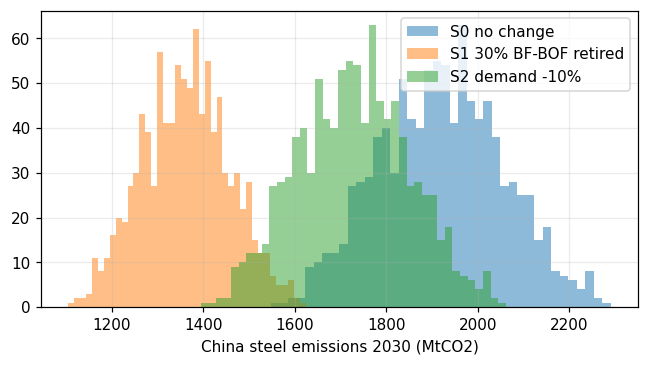

In [39]:
scen = {"S0 no change": dict(), "S1 30% BF-BOF retired": dict(bf_cap_mult=0.7),
        "S2 demand -10%": dict(util_mult=0.9)}
scen_runs = {k: simulate(1000, 2030, **kw) for k, kw in scen.items()}
scen_tab = pd.DataFrame({k: summ(v["national"]) for k, v in scen_runs.items()}).T
scen_tab["width_90"] = scen_tab["p95"] - scen_tab["p5"]
display(scen_tab)
med = scen_tab["median"]
print(f"gap S0-S1 = {med.iloc[0] - med.iloc[1]:,.0f} Mt | gap S0-S2 = {med.iloc[0] - med.iloc[2]:,.0f} Mt"
      f" | width within S0 = {scen_tab['width_90'].iloc[0]:,.0f} Mt")

plt.figure(figsize=(7, 3.5))
for k, v in scen_runs.items():
    plt.hist(v["national"], bins=40, alpha=0.5, label=k)
plt.xlabel("China steel emissions 2030 (MtCO2)"); plt.legend(); plt.show()



(a) 2030, MtCO2:

| Scenario | median | 90% interval |
|---|---|---|
| S0 no change | ≈ 1,921 | [1,700, 2,147] |
| S1 30% BF-BOF retired | ≈ 1,363 | [1,206, 1,520] |
| S2 demand −10% | ≈ 1,729 | [1,530, 1,932] |

(b) The gap between S0 and S1 (≈ 557 Mt) is **bigger** than the width of the interval inside S0 (≈ 447 Mt). The gap between S0 and S2 (≈ 192 Mt) is smaller. So the choice to retire blast furnaces matters more than the statistical uncertainty.

(c) A scenario is a possible future, not something with a known probability. Nobody knows how likely each one is, so a weighted average would be invented, and it would describe a future that does not exist.

## B7. Communicate

Words used by the IPCC for probabilities: **virtually certain** 99-100%, **very likely** 90-100%, **likely** 66-100%, **about as likely as not** 33-66%, **unlikely** 10-33%, **very unlikely** 1-10%, **exceptionally unlikely** 0-1%.

### Q13 [QUANT + QUAL] A probability, a word, and a note

(a) For each scenario, compute the probability that **2030 emissions exceed the 2023 median** (from your `simulate(..., year=2023)`) and give the matching word. (b) Write a note of **about 80 words** for a bank's risk committee about China's steel emissions in 2030. Include: the **median and 90% interval** (baseline), **one sentence on the scenarios**, the **biggest source of uncertainty**, **one limitation** of the model and **one recommended action**. Plain language, no jargon.

> **Hint.** `(draws > threshold).mean()`.

In [40]:
threshold = np.median(sim2023["national"])
print(f"2023 median emissions (model): {threshold:,.0f} MtCO2")

def ipcc_word(p):
    if p >= 0.99: return "virtually certain"
    if p >= 0.90: return "very likely"
    if p >= 0.66: return "likely"
    if p >= 0.33: return "about as likely as not"
    if p >= 0.10: return "unlikely"
    if p >= 0.01: return "very unlikely"
    return "exceptionally unlikely"

q13 = pd.DataFrame({k: {"P(2030 > 2023 median)": (v["national"] > threshold).mean()} for k, v in scen_runs.items()}).T
q13["IPCC wording"] = q13["P(2030 > 2023 median)"].map(ipcc_word)
q13

2023 median emissions (model): 1,943 MtCO2


,P(2030 > 2023 median),IPCC wording
S0 no change,0.44,about as likely as not
S1 30% BF-BOF retired,0.00,exceptionally unlikely
S2 demand -10%,0.04,very unlikely




(a) The threshold is the 2023 median ≈ **1,943 MtCO2**. Probability that 2030 emissions are higher:
* **S0**: ≈ 0.44, *about as likely as not*
* **S1**: ≈ 0.00, *exceptionally unlikely*
* **S2**: ≈ 0.04, *very unlikely*

(b) **Note for the risk committee:**

If nothing changes, China's steel sector will emit about **1.9 billion tonnes of CO2 in 2030** (90% range: 1.7 to 2.1 billion), about the same as today. Closing 30% of blast-furnace capacity would bring it to about 1.4 billion; a 10% drop in demand, to about 1.7 billion. The biggest uncertainty is **how much CO2 each tonne of steel emits**. Limitation: very few plants report their production, so we extrapolate. **Recommendation:** ask steel borrowers for plant-level production and emissions data.